In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Loading CSVs using path.cwd
PROJECT_ROOT = Path.cwd().parent
RAW_DATA = PROJECT_ROOT / "FIFA WC Dataset"
FEATURE_DATA = PROJECT_ROOT / "feature_data"

match_feature = pd.read_csv(FEATURE_DATA / "match_feature_V2.csv")

In [3]:
match_feature.head()


,date,home_team,away_team,home_score,away_score,goal_difference,home_elo,away_elo,elo_diff,home_matches_played,...,away_avg_ga,neutral,tournament,target,home_last5_ppg,away_last5_ppg,home_last5_avg_gf,away_last5_avg_gf,home_last5_avg_ga,away_last5_avg_ga
0,2000-01-04,Egypt,Togo,2,1,1,1500.0,1500.00000,0.00000,0,...,0.0,0,Friendly,2,0.0,0.0,0.0,0.0,0.0,0.0
1,2000-01-07,Tunisia,Togo,7,0,7,1500.0,1496.40065,3.59935,0,...,2.0,0,Friendly,2,0.0,0.0,0.0,1.0,0.0,2.0
2,2000-01-08,Trinidad and Tobago,Canada,0,0,0,1500.0,1500.00000,0.00000,0,...,0.0,0,Friendly,1,0.0,0.0,0.0,0.0,0.0,0.0
3,2000-01-09,Burkina Faso,Gabon,1,1,0,1500.0,1500.00000,0.00000,0,...,0.0,0,Friendly,1,0.0,0.0,0.0,0.0,0.0,0.0
4,2000-01-09,Guatemala,Armenia,1,1,0,1500.0,1500.00000,0.00000,0,...,0.0,1,Friendly,1,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
match_feature.tail()

,date,home_team,away_team,home_score,away_score,goal_difference,home_elo,away_elo,elo_diff,home_matches_played,...,away_avg_ga,neutral,tournament,target,home_last5_ppg,away_last5_ppg,home_last5_avg_gf,away_last5_avg_gf,home_last5_avg_ga,away_last5_avg_ga
23755,2026-07-05,Mexico,England,2,3,-1,1914.033707,1964.601665,-50.567958,473,...,0.775701,0,FIFA World Cup,0,3.0,2.6,2.6,1.8,0.2,0.6
23756,2026-07-06,Portugal,Spain,0,1,-1,1940.716327,2011.585230,-70.868903,336,...,0.707246,1,FIFA World Cup,0,2.2,2.2,2.0,1.8,0.6,0.2
23757,2026-07-06,USA,Belgium,1,4,-3,1812.318122,1861.830427,-49.512304,423,...,1.044828,0,FIFA World Cup,0,1.8,2.2,2.2,2.8,1.2,0.8
23758,2026-07-07,Argentina,Egypt,3,2,1,2064.934264,1801.439090,263.495173,342,...,0.837535,1,FIFA World Cup,2,3.0,1.2,2.6,1.4,0.6,1.2
23759,2026-07-07,Switzerland,Colombia,0,0,0,1882.616182,1957.738735,-75.122554,290,...,0.868098,1,FIFA World Cup,1,2.2,2.6,2.0,1.4,0.8,0.2


In [5]:
match_feature["date"] = pd.to_datetime(match_feature["date"])
print(match_feature["date"].dtype)

datetime64[us]


In [6]:
match_feature.shape

(23760, 26)

In [7]:
match_feature.describe().T

,count,mean,min,25%,50%,75%,max,std
date,23760,2013-05-03 14:32:29.090909,2000-01-04 00:00:00,2006-09-27 00:00:00,2013-03-02 00:00:00,2019-11-16 00:00:00,2026-07-07 00:00:00,NaN
home_score,23760.0,1.605261,0.0,0.0,1.0,2.0,31.0,1.629528
away_score,23760.0,1.077315,0.0,0.0,1.0,2.0,21.0,1.267214
goal_difference,23760.0,0.527946,-21.0,-1.0,0.0,2.0,31.0,2.236053
home_elo,23760.0,1561.482751,880.039309,1456.737006,1562.316384,1675.2541,2089.996965,173.146126
away_elo,23760.0,1547.962962,881.647311,1449.195911,1550.801055,1658.012899,2101.664583,170.287954
elo_diff,23760.0,13.519789,-1045.69938,-91.436634,13.227516,121.376899,1060.996512,185.509342
home_matches_played,23760.0,137.019318,0.0,58.0,123.0,204.0,473.0,94.098912
away_matches_played,23760.0,131.286322,0.0,55.0,117.0,196.0,462.0,90.545476
home_win_pct,23760.0,0.3837,0.0,0.303371,0.388235,0.472222,1.0,0.142205


In [8]:
all_teams = set(match_feature["home_team"]).union(set(match_feature["away_team"]))
print(len(all_teams))

210


## Project Update

The EDA was intentionally paused after discovering that the dataset contains **321 unique teams**, whereas the project is intended to predict matches involving only the **211 official FIFA men's national teams**.

Continuing the analysis on the current dataset would produce results that are no longer representative of the project's objective. Therefore, the decision was made to first filter the raw dataset and rebuild the entire preprocessing pipeline before resuming EDA.

# Exploratory Data Analysis (EDA)

Exploratory analysis of the filtered FIFA match dataset to understand feature distributions, identify data quality issues, detect outliers, analyze class balance, and generate insights for future feature engineering. In short, Continuing where we left off.

In [9]:
# ========================================
# Dataset Overview
# ========================================


print("Dataset Shape")
print(match_feature.shape)


print("Dataset Information")
match_feature.info()


print("Summary Statistics")
display(match_feature.describe())


print("Missing Values")
display(match_feature.isnull().sum().sort_values(ascending=False))


print("Duplicate Rows")
print(match_feature.duplicated().sum())

Dataset Shape
(23760, 26)
Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 23760 entries, 0 to 23759
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   date                 23760 non-null  datetime64[us]
 1   home_team            23760 non-null  str           
 2   away_team            23760 non-null  str           
 3   home_score           23760 non-null  int64         
 4   away_score           23760 non-null  int64         
 5   goal_difference      23760 non-null  int64         
 6   home_elo             23760 non-null  float64       
 7   away_elo             23760 non-null  float64       
 8   elo_diff             23760 non-null  float64       
 9   home_matches_played  23760 non-null  int64         
 10  away_matches_played  23760 non-null  int64         
 11  home_win_pct         23760 non-null  float64       
 12  away_win_pct         23760 non-null  float64       
 

,date,home_score,away_score,goal_difference,home_elo,away_elo,elo_diff,home_matches_played,away_matches_played,home_win_pct,...,home_avg_ga,away_avg_ga,neutral,target,home_last5_ppg,away_last5_ppg,home_last5_avg_gf,away_last5_avg_gf,home_last5_avg_ga,away_last5_avg_ga
count,23760,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000,...,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000,23760.000000
mean,2013-05-03 14:32:29.090909,1.605261,1.077315,0.527946,1561.482751,1547.962962,13.519789,137.019318,131.286322,0.383700,...,1.345133,1.400988,0.268434,1.199327,1.397802,1.358191,1.357483,1.317024,1.308562,1.356817
min,2000-01-04 00:00:00,0.000000,0.000000,-21.000000,880.039309,881.647311,-1045.699380,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2006-09-27 00:00:00,0.000000,0.000000,-1.000000,1456.737006,1449.195911,-91.436634,58.000000,55.000000,0.303371,...,0.975155,1.004306,0.000000,0.000000,0.800000,0.800000,0.800000,0.800000,0.800000,0.800000
50%,2013-03-02 00:00:00,1.000000,1.000000,0.000000,1562.316384,1550.801055,13.227516,123.000000,117.000000,0.388235,...,1.206186,1.246287,0.000000,1.000000,1.400000,1.400000,1.200000,1.200000,1.200000,1.200000
75%,2019-11-16 00:00:00,2.000000,2.000000,2.000000,1675.254100,1658.012899,121.376899,204.000000,196.000000,0.472222,...,1.514742,1.537147,1.000000,2.000000,2.000000,1.800000,1.800000,1.800000,1.600000,1.800000
max,2026-07-07 00:00:00,31.000000,21.000000,31.000000,2089.996965,2101.664583,1060.996512,473.000000,462.000000,1.000000,...,13.500000,15.000000,1.000000,2.000000,3.000000,3.000000,13.600000,16.000000,13.500000,15.000000
std,NaN,1.629528,1.267214,2.236053,173.146126,170.287954,185.509342,94.098912,90.545476,0.142205,...,0.670706,0.753086,0.443154,0.850498,0.720715,0.713591,0.805749,0.792256,0.858218,0.916597


Missing Values


date                   0
home_team              0
away_team              0
home_score             0
away_score             0
goal_difference        0
home_elo               0
away_elo               0
elo_diff               0
home_matches_played    0
away_matches_played    0
home_win_pct           0
away_win_pct           0
home_avg_gf            0
away_avg_gf            0
home_avg_ga            0
away_avg_ga            0
neutral                0
tournament             0
target                 0
home_last5_ppg         0
away_last5_ppg         0
home_last5_avg_gf      0
away_last5_avg_gf      0
home_last5_avg_ga      0
away_last5_avg_ga      0
dtype: int64

Duplicate Rows
0


In [10]:
# ========================================
# Target Distribution
# ========================================

target_map = {
    2: "Home Win",
    1: "Draw",
    0: "Away Win"
}

target_counts = match_feature["target"].value_counts().sort_index()
target_percent = (target_counts / len(match_feature) * 100).round(2)

summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percent
})

summary.index = summary.index.map(target_map)

display(summary)

,Count,Percentage (%)
target,,
Away Win,6697,28.19
Draw,5630,23.70
Home Win,11433,48.12


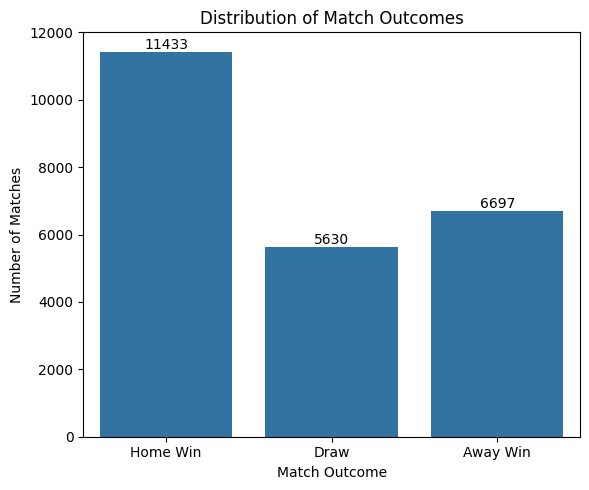

In [11]:
# ========================================
# Target Distribution Plot
plt.figure(figsize=(6,5))

ax = sns.countplot(
    data=match_feature,
    x="target",
    order=[2,1,0]
)

plt.xticks([0,1,2], ["Home Win", "Draw", "Away Win"])
plt.title("Distribution of Match Outcomes")
plt.xlabel("Match Outcome")
plt.ylabel("Number of Matches")

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [12]:
# Numerical Features

numeric_features = match_feature.select_dtypes(include=["number"]).columns.tolist()

# Remove target variable
numeric_features.remove("target")

print(f"Number of numerical features: {len(numeric_features)}")
print(numeric_features)

Number of numerical features: 21
['home_score', 'away_score', 'goal_difference', 'home_elo', 'away_elo', 'elo_diff', 'home_matches_played', 'away_matches_played', 'home_win_pct', 'away_win_pct', 'home_avg_gf', 'away_avg_gf', 'home_avg_ga', 'away_avg_ga', 'neutral', 'home_last5_ppg', 'away_last5_ppg', 'home_last5_avg_gf', 'away_last5_avg_gf', 'home_last5_avg_ga', 'away_last5_avg_ga']


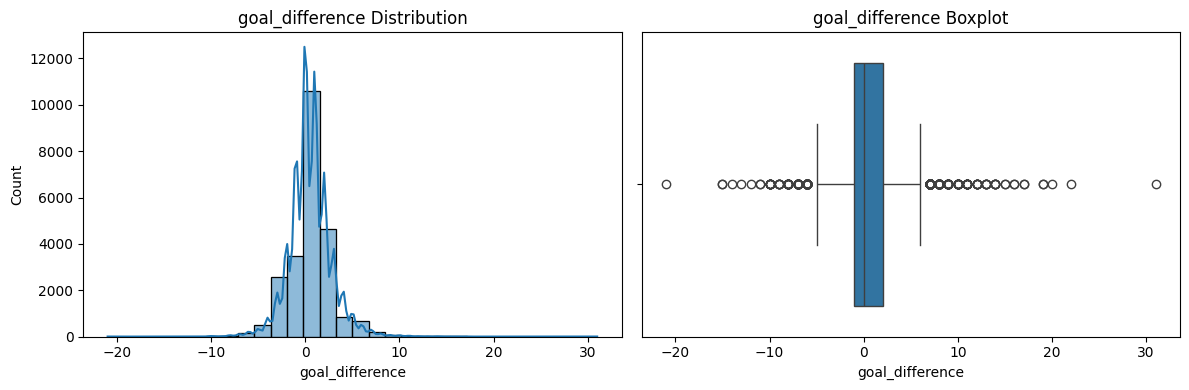

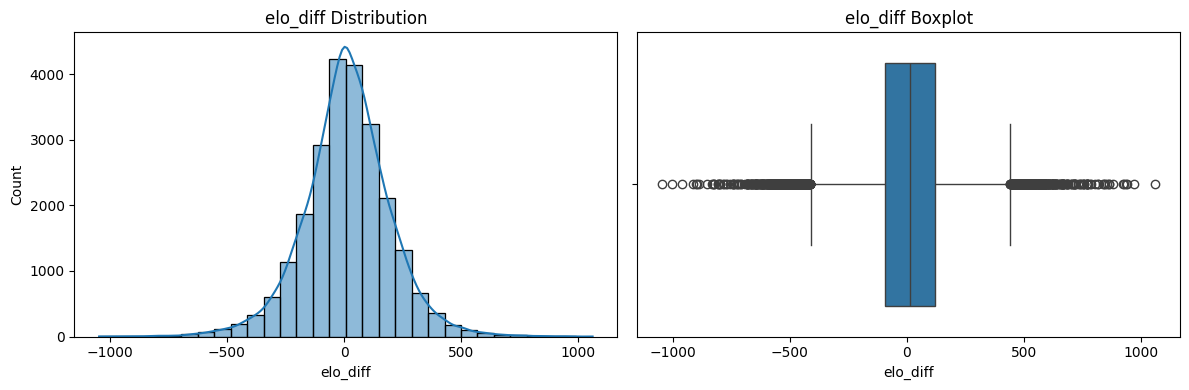

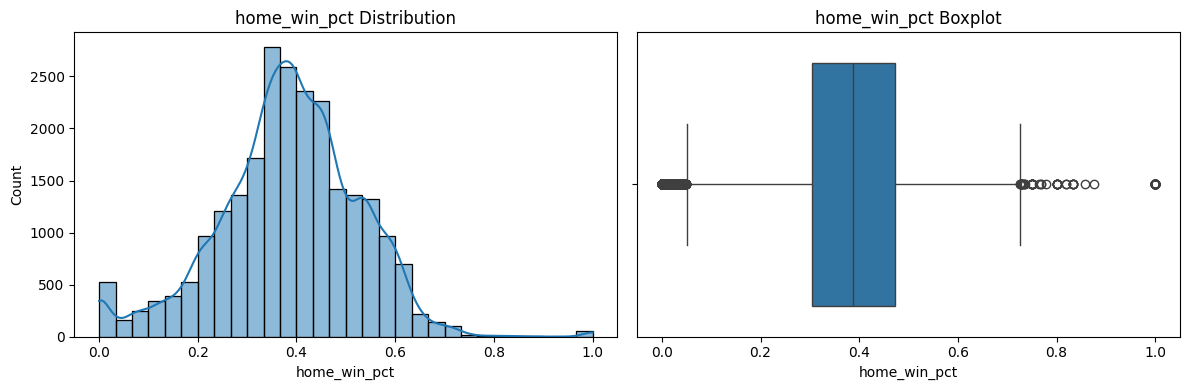

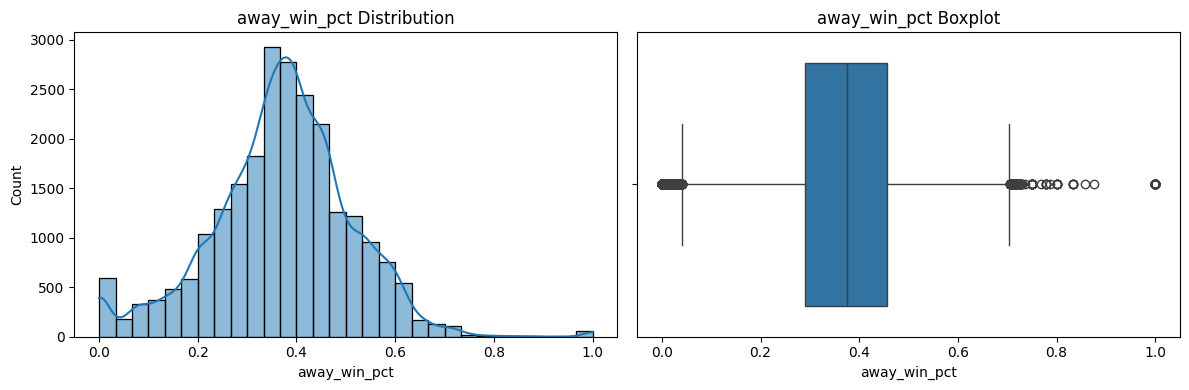

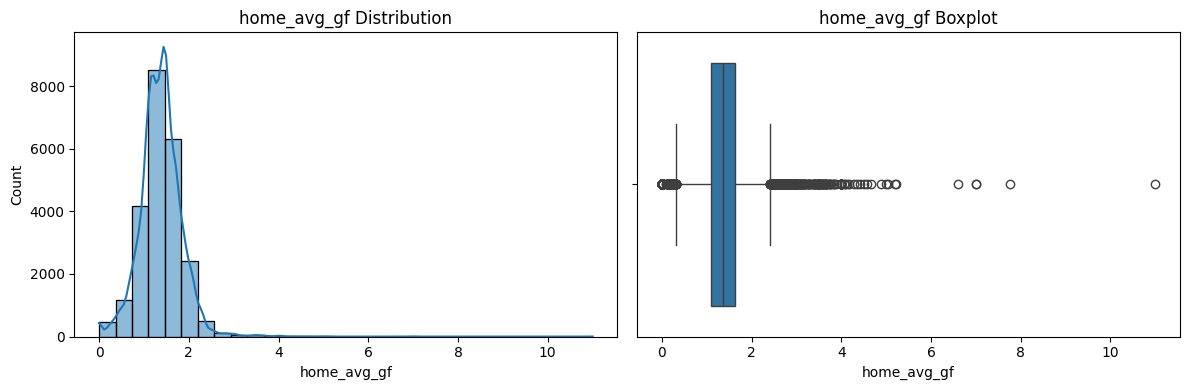

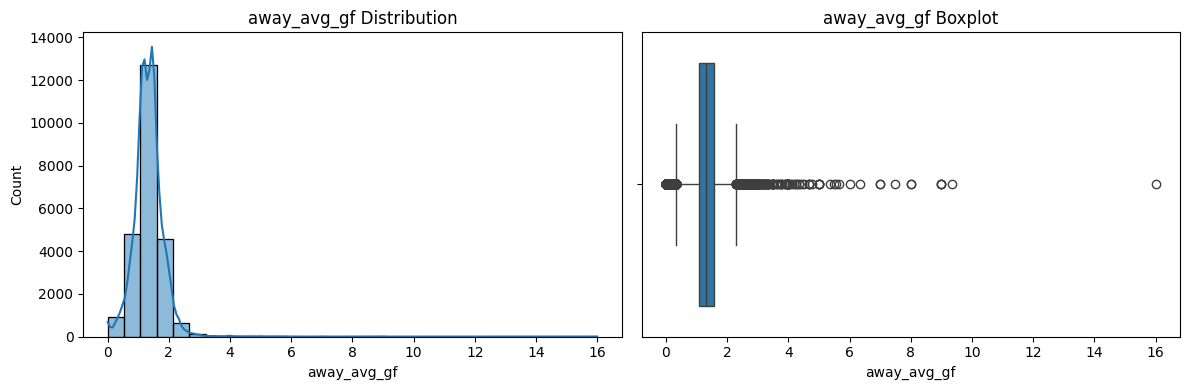

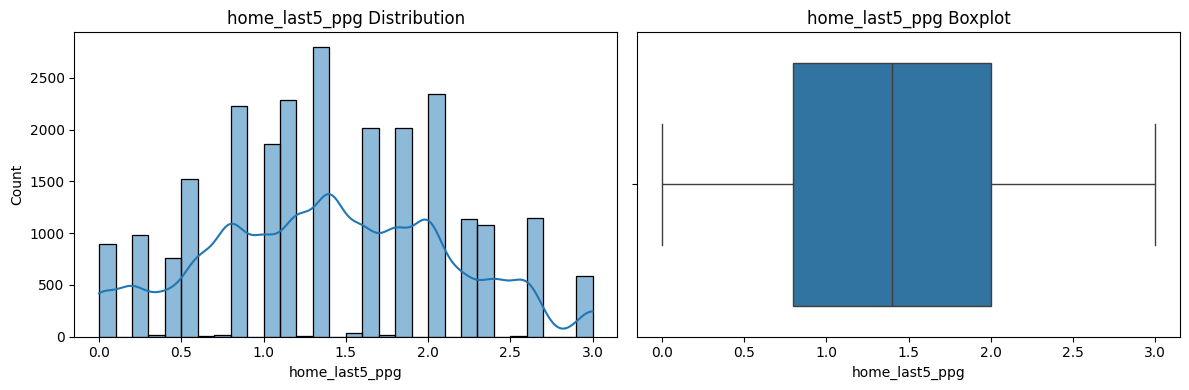

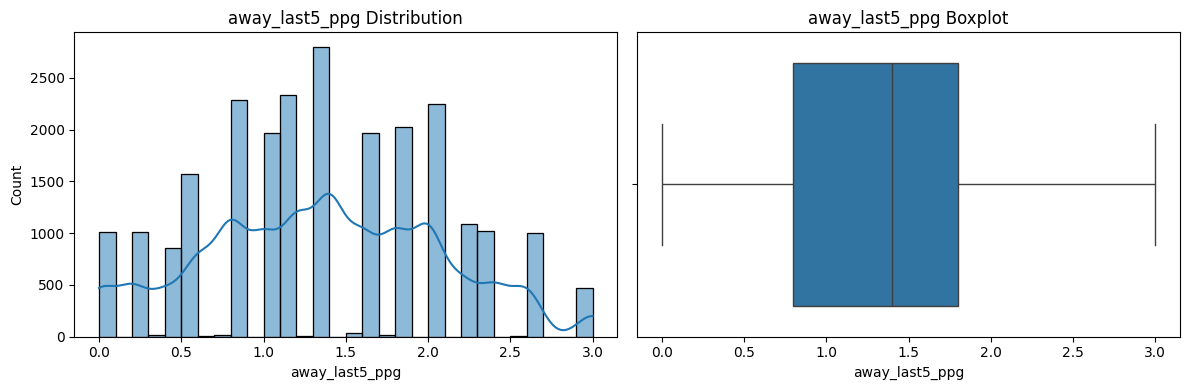

In [13]:
# Numerical Feature Analysis

features_to_plot = [
    "goal_difference",
    "elo_diff",
    "home_win_pct",
    "away_win_pct",
    "home_avg_gf",
    "away_avg_gf",
    "home_last5_ppg",
    "away_last5_ppg"
]

for feature in features_to_plot:

    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Histogram
    sns.histplot(match_feature[feature], bins=30, kde=True, ax=axes[0])
    axes[0].set_title(f"{feature} Distribution")

    # Boxplot
    sns.boxplot(x=match_feature[feature], ax=axes[1])
    axes[1].set_title(f"{feature} Boxplot")

    plt.tight_layout()
    plt.show()

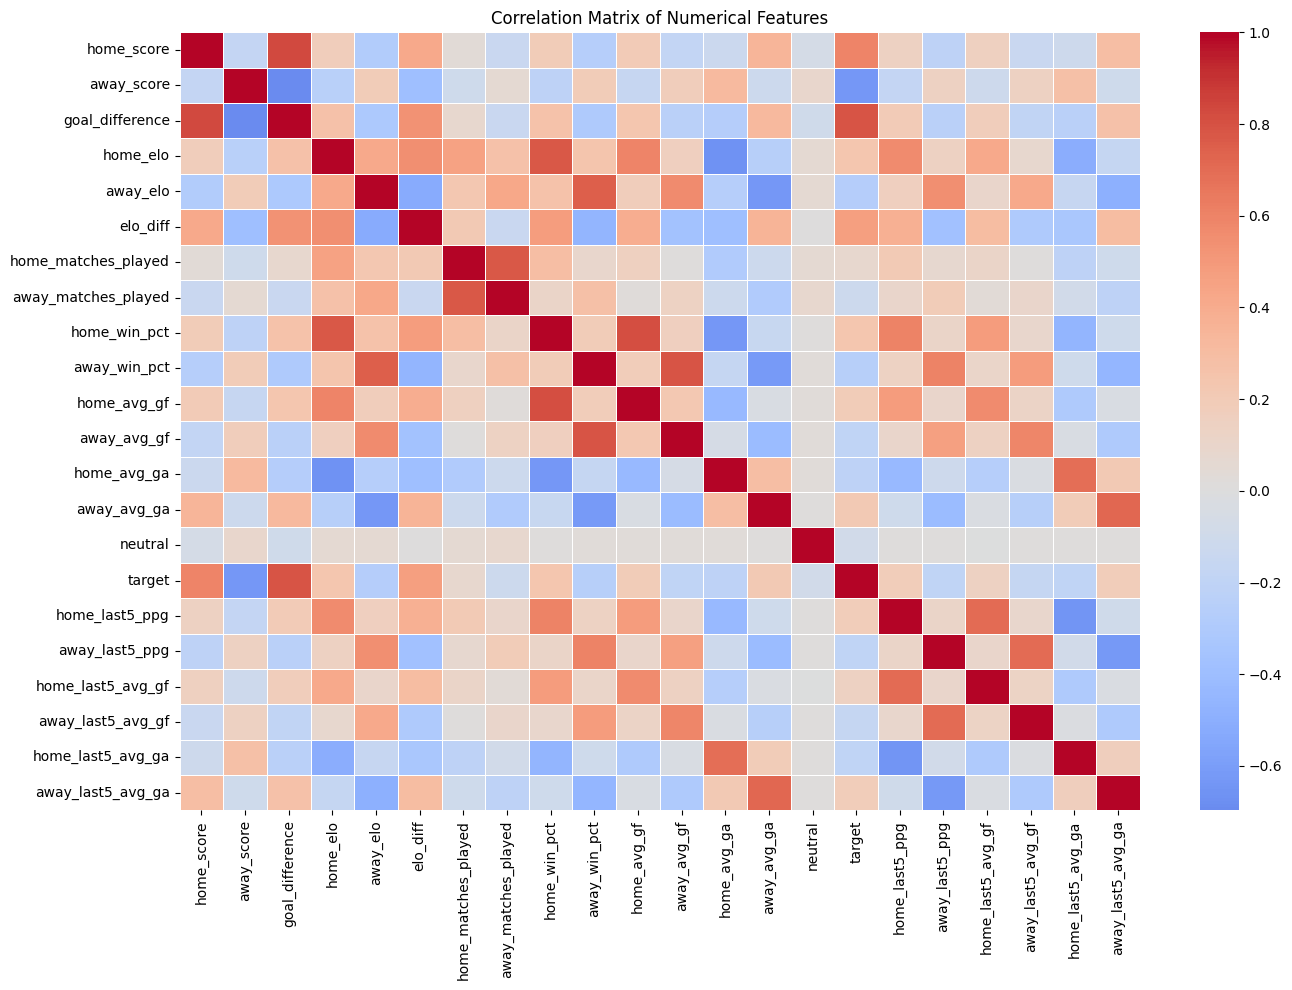

In [14]:
# Correlation Matrix


corr_matrix = match_feature.select_dtypes(include="number").corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [15]:
# Strong Feature Correlations


corr = match_feature.select_dtypes(include="number").corr().abs()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

strong_corr = (
    upper.stack()
         .sort_values(ascending=False)
)

display(strong_corr[strong_corr >= 0.70].to_frame("Correlation"))

,,Correlation
home_score,goal_difference,0.830124
home_win_pct,home_avg_gf,0.811692
away_win_pct,away_avg_gf,0.792369
goal_difference,target,0.790849
home_matches_played,away_matches_played,0.774338
home_elo,home_win_pct,0.768983
away_elo,away_win_pct,0.751705
away_avg_ga,away_last5_avg_ga,0.716665
home_last5_ppg,home_last5_avg_gf,0.707970
away_last5_ppg,away_last5_avg_gf,0.703763


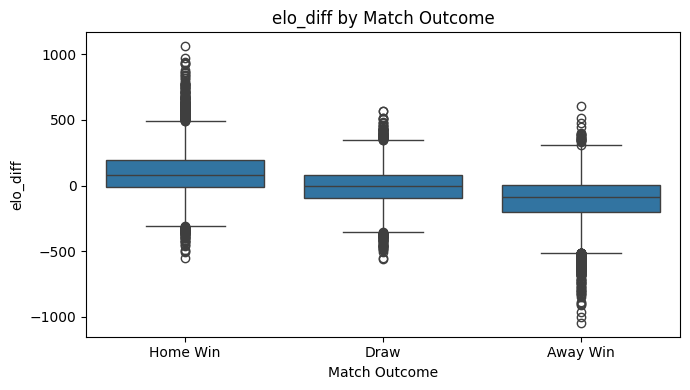

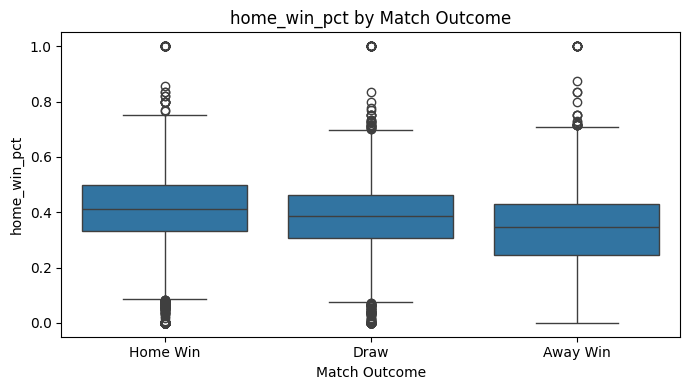

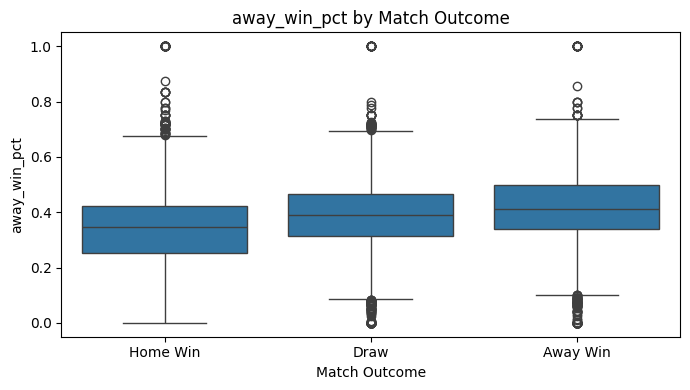

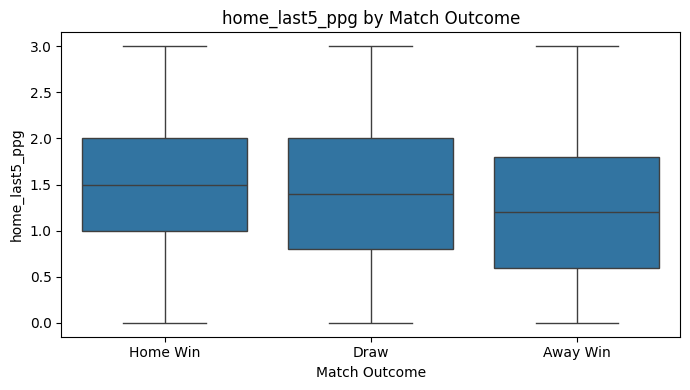

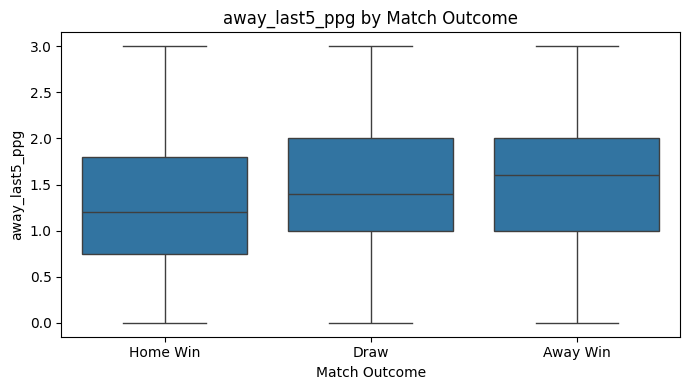

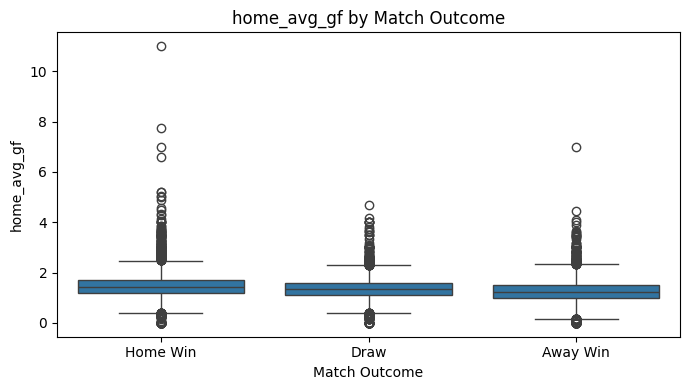

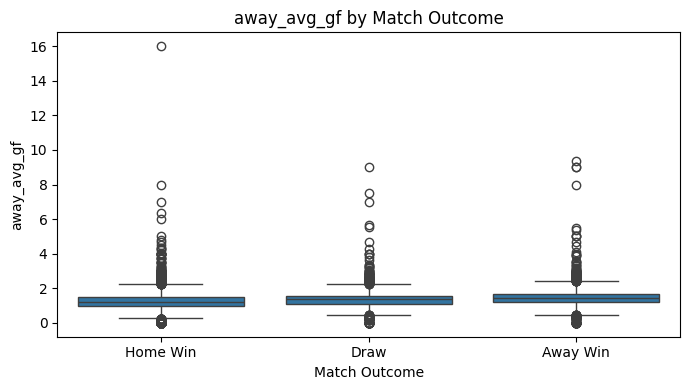

In [16]:
# Feature vs Target


features = [
    "elo_diff",
    "home_win_pct",
    "away_win_pct",
    "home_last5_ppg",
    "away_last5_ppg",
    "home_avg_gf",
    "away_avg_gf"
]

target_labels = {
    2: "Home Win",
    1: "Draw",
    0: "Away Win"
}

df_plot = match_feature.copy()
df_plot["target"] = df_plot["target"].map(target_labels)

for feature in features:

    plt.figure(figsize=(7,4))

    sns.boxplot(
        data=df_plot,
        x="target",
        y=feature,
        order=["Home Win", "Draw", "Away Win"]
    )

    plt.title(f"{feature} by Match Outcome")
    plt.xlabel("Match Outcome")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

`Exploratory Data Analysis` (with some visuals) is finished above. Now, from below cells, i will check and select which new *Match Features* will help in future Models and better *Draw* Predicitons.

In [ ]:
# Creating abs_elo_diff feature:

match_feature["abs_elo_diff"] = match_feature["elo_diff"].abs()

In [33]:
print(match_feature[["home_team", "away_team", "elo_diff"]].loc[560])
print(match_feature[["home_team", "away_team", "abs_elo_diff"]].loc[560])

# abs_elo feature working correctly.

home_team      Czechia
away_team       France
elo_diff    -77.605804
Name: 560, dtype: object
home_team         Czechia
away_team          France
abs_elo_diff    77.605804
Name: 560, dtype: object


In [ ]:
# Creating 'win_pct_gap' feature:

match_feature["win_pct_gap"] = (
    match_feature["home_win_pct"] - match_feature["away_win_pct"]
).abs()

In [ ]:
print(match_feature[["home_team", "away_team", "home_win_pct", "away_win_pct"]].loc[4500])
print(match_feature[["home_team", "away_team", "win_pct_gap"]].loc[4500])

# win_pct_gap feature working correctly

home_team         Russia
away_team        Estonia
home_win_pct    0.428571
away_win_pct    0.307692
Name: 4500, dtype: object
home_team        Russia
away_team       Estonia
win_pct_gap    0.120879
Name: 4500, dtype: object


In [ ]:
# Creating 'last5_ppg_gap' feature:

match_feature["last5_ppg_gap"] = (
    match_feature["home_last5_ppg"] - match_feature["away_last5_ppg"]
).abs()

In [ ]:
print(match_feature[["home_team", "away_team", "home_last5_ppg", "away_last5_ppg"]].loc[19000])
print(match_feature[["home_team", "away_team", "last5_ppg_gap"]].loc[19000])
print(match_feature[["home_team", "away_team", "home_last5_ppg", "away_last5_ppg"]].loc[19200])
print(match_feature[["home_team", "away_team", "last5_ppg_gap"]].loc[19200])

# last5_ppg_gap feature working correctly.

home_team         Kosovo
away_team          Spain
home_last5_ppg       2.0
away_last5_ppg       1.6
Name: 19000, dtype: object
home_team        Kosovo
away_team         Spain
last5_ppg_gap       0.4
Name: 19000, dtype: object
home_team              Benin
away_team         Madagascar
home_last5_ppg           1.4
away_last5_ppg           0.8
Name: 19200, dtype: object
home_team             Benin
away_team        Madagascar
last5_ppg_gap           0.6
Name: 19200, dtype: object


In [52]:
# Creating 'avg_gf_gap' feature:

match_feature["avg_gf_gap"] = (
    match_feature["home_avg_gf"] - match_feature["away_avg_gf"]
).abs()

In [67]:
print(match_feature[["home_team", "away_team", "home_avg_gf", "away_avg_gf"]].loc[23670])
print(match_feature[["home_team", "away_team", "avg_gf_gap"]].loc[23670])
print(match_feature[["home_team", "away_team", "home_avg_gf", "away_avg_gf"]].loc[23674])
print(match_feature[["home_team", "away_team", "avg_gf_gap"]].loc[23674])

# avg_gf_gap feature is working correctly.

home_team            Qatar
away_team      Switzerland
home_avg_gf       1.472422
away_avg_gf       1.657343
Name: 23670, dtype: object
home_team           Qatar
away_team     Switzerland
avg_gf_gap       0.184921
Name: 23670, dtype: object
home_team      Netherlands
away_team            Japan
home_avg_gf       2.097179
away_avg_gf       1.949495
Name: 23674, dtype: object
home_team     Netherlands
away_team           Japan
avg_gf_gap       0.147684
Name: 23674, dtype: object


In [69]:
# Creating 'avg_ga_gap' feature:

match_feature["avg_ga_gap"] = (
    match_feature["home_avg_ga"] - match_feature["away_avg_ga"]
).abs()

In [74]:
print(match_feature[["home_team", "away_team", "home_avg_ga", "away_avg_ga"]].loc[18956])
print(match_feature[["home_team", "away_team", "avg_ga_gap"]].loc[18956])
print(match_feature[["home_team", "away_team", "home_avg_ga", "away_avg_ga"]].loc[19856])
print(match_feature[["home_team", "away_team", "avg_ga_gap"]].loc[19856])

home_team       Austria
away_team      Scotland
home_avg_ga    1.328431
away_avg_ga     1.26455
Name: 18956, dtype: object
home_team      Austria
away_team     Scotland
avg_ga_gap    0.063881
Name: 18956, dtype: object
home_team      Korea Republic
away_team            Paraguay
home_avg_ga          0.892754
away_avg_ga          1.267925
Name: 19856, dtype: object
home_team     Korea Republic
away_team           Paraguay
avg_ga_gap          0.375171
Name: 19856, dtype: object


## Match Feature V3

Based on the EDA findings, i added five new balance-based engineered features to improve the model's ability to identify closely matched teams and potentially improve draw prediction.

**New Features Added:**
- `abs_elo_diff`
- `win_pct_gap`
- `last5_ppg_gap`
- `avg_gf_gap`
- `avg_ga_gap`